<a href="https://colab.research.google.com/github/hajar945/lopsided/blob/main/notebooks/lopsided_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lopsided — prediction images and the one-patient demo
**No new experiments.** This notebook re-trains ONE model (fold 0) with the exact recipe of the main experiment, checks that it reproduces the main run's per-patient scores, then draws (1) a failure gallery with prediction images and (2) a one-patient demo with plain-language reasons and the trust flag. It reuses the same feature and model code as `lopsided_v4h.ipynb`. **CPU runtime, about 15-25 minutes.** Run everything from the top with `QUICK = False`; the cache and the main-run checkpoint from the earlier runs must be in Drive.

Colours: **green outline = expert-marked lesion, red outline = model prediction.**

In [ ]:
!pip install -q nibabel pyarrow pandas numpy matplotlib scipy scikit-learn tqdm xgboost shap torch
from google.colab import drive
import os, glob, json, gc, time, pickle, tempfile, warnings, math
from collections import Counter
import numpy as np, pandas as pd, nibabel as nib
import pyarrow as pa, pyarrow.parquet as pq
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import psutil
warnings.filterwarnings('ignore')
def ram(tag=''): print(f'[RAM {tag}] this notebook = {psutil.Process().memory_info().rss / 1e9:.1f} GB | machine has {psutil.virtual_memory().available / 1e9:.1f} GB free')
drive.mount('/content/drive')

QUICK   = False          # True = tiny smoke test (24 patients, 2 folds, 2 epochs). Set False for the real run.
PROJECT = '/content/drive/MyDrive/isles_data'
NB_VER = 'v4f'          # tags the saved-progress files. DO NOT change it unless model code changes: the finished simple-model results are reused through this tag.
NB_BUILD = 'demo'          # saved-progress files are tagged with this, so an old run can never be reused by a newer notebook
DS = 4                  # in-plane downsample (4 -> ~1.6 x 1.6 x 2 mm voxels). DS=2 needs ~11 GB just for features and crashes Colab.
CACHE3  = os.path.join(PROJECT, f'v3_cache_ds{DS}'); os.makedirs(CACHE3, exist_ok=True)
FOLDS   = os.path.join(PROJECT, 'folds.csv')           # from Week 2: patient-level folds (empty-mask patients already excluded)
FEATS_V2= os.path.join(PROJECT, 'features_v2.csv')     # from Week 2: lesion descriptors for failure analysis
RESULTS = os.path.join(PROJECT, 'v3_results.pkl')

MAPS = ('cbf', 'cbv', 'mtt', 'tmax')
CAPS = {'cbf': 150, 'cbv': 40, 'mtt': 40, 'tmax': 20}
SEED = 0
REFIT = False         # both model families train on 80% of the training patients and use the other 20% to choose settings + threshold; no refit. Equal for everyone, and it halves GPU time.
DELTA = 0.05            # PRE-REGISTERED equivalence margin on mean-patient Dice (set from measurement noise, NOT from results; never change after seeing results)
THR = np.round(np.arange(0.1, 0.91, 0.05), 2)

shards = sorted(glob.glob(os.path.join(PROJECT, 'data', '*.parquet')))
folds = pd.read_csv(FOLDS)
FOLD = dict(zip(folds['subject_id'], folds['fold']))
COHORT = folds['subject_id'].tolist()
if QUICK: COHORT = COHORT[:24]
FOLDS_TO_RUN = [0, 1] if QUICK else [0, 1, 2, 3, 4]
print('NOTEBOOK VERSION:', NB_BUILD, '(checkpoint tag', NB_VER, ') (DS =', DS, ')  <- if you do not see this line, you are running an old copy')
print(len(shards), 'shards |', len(COHORT), 'patients in cohort | QUICK =', QUICK)

Mounted at /content/drive
NOTEBOOK VERSION: demo (checkpoint tag v4f ) (DS = 4 )  <- if you do not see this line, you are running an old copy
149 shards | 147 patients in cohort | QUICK = False


In [ ]:
sch0 = pq.read_schema(shards[0])
IMG_COLS  = {f.name for f in sch0 if pa.types.is_struct(f.type)}
META_COLS = [f.name for f in sch0 if f.name not in IMG_COLS]
print('scalar metadata columns:', META_COLS)
print('image/struct columns   :', sorted(IMG_COLS))
# >>> LOOK AT THE PRINTOUT ABOVE and fill these in if such columns exist <<<
SITE_COL    = None     # column naming the hospital/center/scanner, if any
OUTCOME_COL = None     # e.g. a 90-day mRS column, if any (optional stretch goal)

def load_nifti(struct):
    if not struct or struct.get('bytes') is None: return None
    raw, path = struct['bytes'], (struct.get('path') or 'img.nii.gz')
    suffix = '.nii.gz' if path.endswith('.gz') else '.nii'
    with tempfile.NamedTemporaryFile(suffix=suffix, delete=False) as tf:
        tf.write(raw); tmp = tf.name
    try:
        img = nib.load(tmp); arr = np.asanyarray(img.dataobj).astype(np.float32)
        if arr.ndim > 3: arr = arr[..., 0]
        return arr, nib.aff2axcodes(img.affine), tuple(float(z) for z in img.header.get_zooms()[:3])
    finally:
        os.remove(tmp)

def read_row(shard_path, tries=4):
    cols = META_COLS + list(MAPS) + ['lesion_mask']
    for t in range(tries):
        try:
            return pq.read_table(shard_path, columns=cols).slice(0, 1).to_pylist()[0]
        except OSError as e:
            print('Drive hiccup, remounting', t + 1); time.sleep(5)
            try: drive.mount('/content/drive', force_remount=True)
            except Exception as e2: print('remount failed', e2)
    raise OSError('Drive stayed disconnected; re-run setup cell.')

def load_patient(shard_path):
    row = read_row(shard_path)
    meta = {c: row.get(c) for c in META_COLS}
    vols, codes, zooms = {}, None, None
    for k in MAPS:
        r = load_nifti(row[k])
        if r is None: vols[k] = None; continue
        vols[k] = np.clip(r[0], 0, None)
        if codes is None: codes, zooms = r[1], r[2]
    m = load_nifti(row['lesion_mask']); mask = None if m is None else (m[0] > 0)
    if codes is not None and any(v is None for v in vols.values()) is False:
        flipx = codes[0] == 'L'          # standardise: low x = left
        flipy = codes[1] == 'P'          # standardise: high y = anterior
        def fl(a):
            if flipx: a = a[::-1]
            if flipy: a = a[:, ::-1]
            return np.ascontiguousarray(a)
        vols = {k: fl(v) for k, v in vols.items()}
        if mask is not None: mask = fl(mask)
    return meta, vols, mask, codes, zooms

def make_brain_mask(vols):
    m = None
    for k in MAPS:
        cur = np.isfinite(vols[k]) & (vols[k] > 0); m = cur if m is None else (m | cur)
    for z in range(m.shape[2]):
        if m[:, :, z].any(): m[:, :, z] = ndi.binary_fill_holes(m[:, :, z])
    return m

def find_extent(brain, axis_keep):
    per = brain.sum(axis=axis_keep); keep = np.nonzero(per > 0.01 * per.max())[0]
    return int(keep.min()), int(keep.max())

def find_midline(brain):
    xmin, xmax = find_extent(brain, (1, 2)); return (xmin + xmax) / 2.0, xmin, xmax

scalar metadata columns: ['subject_id', 'age', 'sex', 'nihss_admission', 'mrs_admission', 'mrs_3month']
image/struct columns   : ['adc', 'cbf', 'cbv', 'cow_segmentation', 'cta', 'ctp', 'dwi', 'lesion_mask', 'lvo_mask', 'mtt', 'ncct', 'tmax']


In [ ]:
def preprocess(shard):
    meta, vols, mask, codes, zooms = load_patient(shard)
    if mask is None or any(v is None for v in vols.values()): return None
    brain = make_brain_mask(vols)
    arr = np.stack([np.nan_to_num(np.clip(vols[k], 0, CAPS[k]), nan=0.0, posinf=CAPS[k]) for k in MAPS])
    f = (1 / DS, 1 / DS, 1)
    arr_s = np.stack([ndi.zoom(a, f, order=1) for a in arr])
    brain_s = ndi.zoom(brain.astype(np.uint8), f, order=0) > 0
    mask_s = ndi.zoom(mask.astype(np.uint8), f, order=0) > 0
    mid, _, _ = find_midline(brain_s)
    meta.update(orig_shape=list(vols['cbf'].shape), zooms=list(zooms), axis_codes=list(codes),
                vox_ml=float(zooms[0] * DS * zooms[1] * DS * zooms[2] / 1000.0), mid=float(mid))
    out = (meta, arr_s.astype(np.float16), brain_s, mask_s)
    del vols, arr, arr_s, brain, mask; gc.collect()
    return out

todo = shards if not QUICK else shards[:len(COHORT) + 10]
for sh in tqdm(todo):
    stem = os.path.basename(sh).replace('.parquet', '')
    jp, zp = os.path.join(CACHE3, stem + '.json'), os.path.join(CACHE3, stem + '.npz')
    if os.path.exists(jp): continue
    try:
        out = preprocess(sh)
        if out is None: continue
        meta, a, b, m = out
        np.savez_compressed(zp, arr=a, brain=b, mask=m)
        with open(jp, 'w') as fh: json.dump(meta, fh, default=str)
    except Exception as e:
        print('FAILED', stem, repr(e))
    gc.collect()

ram('after caching')
def get(sid):      # volumes are read from the Drive cache on demand, one patient at a time (keeps RAM low)
    z = np.load(P[sid]['path']); return dict(arr=z['arr'], brain=z['brain'], mask=z['mask'], mid=P[sid]['mid'], vox_ml=P[sid]['vox_ml'])

P, META = {}, {}
for jp in sorted(glob.glob(os.path.join(CACHE3, '*.json'))):
    meta = json.load(open(jp)); sid = meta['subject_id']
    if sid not in COHORT: continue
    P[sid] = dict(path=jp.replace('.json', '.npz'), mid=meta['mid'], vox_ml=meta['vox_ml'])
    META[sid] = meta
IDS = [s for s in COHORT if s in P]
print(len(IDS), 'patients cached | example grid:', get(IDS[0])['arr'].shape); ram('after loading cache')

  0%|          | 0/149 [00:00<?, ?it/s]

[RAM after caching] this notebook = 0.3 GB | machine has 12.2 GB free
147 patients cached | example grid: (4, 128, 149, 75)
[RAM after loading cache] this notebook = 0.3 GB | machine has 9.9 GB free


In [ ]:
def mirror_vol(v, mid):
    X = v.shape[0]; xm = np.rint(2 * mid - np.arange(X)).astype(int); ok = (xm >= 0) & (xm < X)
    out = np.full(v.shape, np.nan, np.float32); out[ok] = v[xm[ok]]; return out

In [ ]:
FEAT_GROUP = {}
def nsmooth(v, brain, s=(1.5, 1.5, 0.75)):
    w = ndi.gaussian_filter(brain.astype(np.float32), s)
    return ndi.gaussian_filter(np.where(brain, v, 0).astype(np.float32), s) / np.maximum(w, 1e-3)

def voxel_features(arr, brain, mid):
    arr = arr.astype(np.float32); cols, names = [], []
    def add(name, vol, group):
        cols.append(vol[brain]); names.append(name); FEAT_GROUP[name] = group
    for i, k in enumerate(MAPS):
        v = arr[i]; med = float(np.median(v[brain])) + 1e-6
        mv = mirror_vol(np.where(brain, v, np.nan), mid)
        add(f'raw_{k}', v, 'raw')
        add(f'rel_{k}', np.clip(v / med, 0, 20), 'relative')
        if k == 'cbf': add('relp75_cbf', np.clip(v / (float(np.percentile(v[brain], 75)) + 1e-6), 0, 20), 'relative')   # robust 'normal flow' reference
        add(f'mir_{k}', v - mv, 'mirror')
        if k in ('cbf', 'cbv'): add(f'mirratio_{k}', np.clip(v / (mv + 1e-3 * CAPS[k]), 0, 5), 'mirror')
        s = nsmooth(v, brain); sm = mirror_vol(np.where(brain, s, np.nan), mid)
        add(f'sm_{k}', s, 'context'); add(f'smmir_{k}', s - sm, 'context')
        if k == 'tmax':
            s2 = nsmooth(v * v, brain); add('lstd_tmax', np.sqrt(np.maximum(s2 - s * s, 0)), 'context')
    X, Y, Z = brain.shape
    ymin, ymax = find_extent(brain, (0, 2)); zs = np.nonzero(brain.any(axis=(0, 1)))[0]
    bc = lambda a, ax: np.broadcast_to(a.reshape([-1 if i == ax else 1 for i in range(3)]), brain.shape)
    add('pos_midline_dist', bc(np.abs(np.arange(X) - mid), 0), 'position')
    add('pos_front_back', bc((np.arange(Y) - ymin) / max(ymax - ymin, 1), 1), 'position')
    add('pos_up_down', bc((np.arange(Z) - zs.min()) / max(zs.max() - zs.min(), 1), 2), 'position')
    return np.stack(cols, 1).astype(np.float16), names, np.flatnonzero(brain)

FEAT = {}
for sid in tqdm(IDS):
    p = get(sid); F, names, bidx = voxel_features(p['arr'], p['brain'], p['mid'])
    FEAT[sid] = dict(F=F, y=p['mask'].reshape(-1)[bidx].astype(np.uint8), les_total=int(p['mask'].sum()),
                     vox_ml=p['vox_ml'], n=len(bidx))
    del p; gc.collect()
FEAT_NAMES = names; IDX = {n: i for i, n in enumerate(FEAT_NAMES)}; ALLC = list(range(len(FEAT_NAMES)))
print(len(FEAT_NAMES), 'features:', FEAT_NAMES)
print('feature RAM (GB):', round(sum(d['F'].nbytes for d in FEAT.values()) / 1e9, 2))
assert not any(n.startswith(('lesion', 'les_', 'reg_')) for n in FEAT_NAMES)   # leakage guard
ram('after features')

  0%|          | 0/147 [00:00<?, ?it/s]

27 features: ['raw_cbf', 'rel_cbf', 'relp75_cbf', 'mir_cbf', 'mirratio_cbf', 'sm_cbf', 'smmir_cbf', 'raw_cbv', 'rel_cbv', 'mir_cbv', 'mirratio_cbv', 'sm_cbv', 'smmir_cbv', 'raw_mtt', 'rel_mtt', 'mir_mtt', 'sm_mtt', 'smmir_mtt', 'raw_tmax', 'rel_tmax', 'mir_tmax', 'sm_tmax', 'smmir_tmax', 'lstd_tmax', 'pos_midline_dist', 'pos_front_back', 'pos_up_down']
feature RAM (GB): 3.32
[RAM after features] this notebook = 3.9 GB | machine has 7.8 GB free


In [ ]:
def col(sid, name): return FEAT[sid]['F'][:, IDX[name]].astype(np.float32)

def score_pred(pred, sid):
    d = FEAT[sid]; tp = int((pred & (d['y'] == 1)).sum())
    return 2 * tp / (int(pred.sum()) + d['les_total'] + 1e-9), float(pred.sum()) * d['vox_ml']

RULES = {'rule_tmax6': lambda s: col(s, 'raw_tmax') > 6,
         'rule_core': lambda s: (col(s, 'raw_tmax') > 6) & (col(s, 'relp75_cbf') < 0.30)}   # clinical 'core': low flow (<30% of a robust normal-flow reference) INSIDE the delayed-flow region (Tmax>6 s)
CANDS = [('raw_tmax', 1), ('sm_tmax', 1), ('smmir_tmax', 1), ('mir_tmax', 1), ('rel_mtt', 1), ('rel_cbf', -1), ('relp75_cbf', -1), ('rel_cbv', -1)]

def fit_rule(train, max_eval=40, seed=0):
    rng = np.random.default_rng(seed); ev = list(rng.choice(train, min(max_eval, len(train)), replace=False))
    best = (-1, None)
    for name, s in CANDS:
        vals = {p: s * col(p, name) for p in ev}
        pooled = np.concatenate([v[::20] for v in vals.values()]); pooled = pooled[np.isfinite(pooled)]
        for t in np.unique(np.quantile(pooled, np.linspace(0.5, 0.99, 20))):
            dm = np.mean([score_pred(vals[p] > t, p)[0] for p in ev])
            if dm > best[0]: best = (dm, (name, s, float(t)))
    return best[1]

def rule_pred(rule, sid): name, s, t = rule; return (s * col(sid, name)) > t

rd = pd.DataFrame({k: [score_pred(f(s), s)[0] for s in IDS] for k, f in RULES.items()}, index=IDS)
print('Fixed clinical rules, mean Dice over all patients (no training involved):'); print(rd.mean().round(3).to_string())

Fixed clinical rules, mean Dice over all patients (no training involved):
rule_tmax6    0.135
rule_core     0.097


In [ ]:
import xgboost as xgb
GBM_GRID = [dict(max_depth=d, n_estimators=300) for d in (3, 5)]
if QUICK: GBM_GRID = GBM_GRID[:2]

def sample_train(pids, rng, npos=2500, nneg=2500):
    Xs, ys = [], []
    for p in pids:
        d = FEAT[p]; y = d['y']; ip, ineg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
        if len(ip): ip = rng.choice(ip, min(npos, len(ip)), replace=False)
        ineg = rng.choice(ineg, min(nneg, len(ineg)), replace=False); idx = np.concatenate([ip, ineg])
        Xs.append(d['F'][idx]); ys.append(y[idx])
    return np.concatenate(Xs).astype(np.float32), np.concatenate(ys)

def predict_p(model, sid, cols): return model.predict_proba(FEAT[sid]['F'][:, cols].astype(np.float32))[:, 1]

def sweep_thr(probs, pids, dicefn):
    sc = [np.mean([dicefn(probs[s], t, s) for s in pids]) for t in THR]; i = int(np.argmax(sc)); return float(THR[i]), float(sc[i])

gbm_dice = lambda p, t, s: score_pred(p > t, s)[0]

def make_xgb(h, seed): return xgb.XGBClassifier(**h, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                                                 n_jobs=-1, random_state=seed, eval_metric='logloss')

def fit_gbm(train, seed=0, hp=None, cols=None):
    cols = cols or ALLC; rng = np.random.default_rng(seed); tp = list(rng.permutation(train))
    nv = max(3, int(0.2 * len(tp))); val, fit = tp[:nv], tp[nv:]
    X, y = sample_train(fit, rng); best = None
    for h in ([hp] if hp else GBM_GRID):
        m = make_xgb(h, seed).fit(X[:, cols], y); pv = {s: predict_p(m, s, cols) for s in val}
        thr, dv = sweep_thr(pv, val, gbm_dice)
        if best is None or dv > best[0]: best = (dv, thr, h, m)
    if not REFIT: return dict(model=best[3], thr=best[1], hp=best[2], cols=cols)
    X, y = sample_train(list(train), rng)
    return dict(model=make_xgb(best[2], seed).fit(X[:, cols], y), thr=best[1], hp=best[2], cols=cols)

## 1. Re-train fold 0 with the main-experiment recipe, and check it reproduces




In [ ]:
CKM = os.path.join(PROJECT, f'ck_main_{NB_VER}_ds{DS}' + ('_quick' if QUICK else '') + '.pkl')
main = pd.DataFrame(pickle.load(open(CKM, 'rb'))['MAIN'])
f0 = 0; tr = [s for s in IDS if FOLD[s] != f0]; te = [s for s in IDS if FOLD[s] == f0]
M = fit_gbm(tr, SEED)                                    # identical recipe: 2 settings, validation patients, Dice-tuned threshold, no refit
def pred_prob_volume(sid):
    b = get(sid)['brain']; vol = np.zeros(b.size, np.float32); vol[np.flatnonzero(b)] = predict_p(M['model'], sid, M['cols']); return vol.reshape(b.shape)
rows = []
for s in te:
    d, v = score_pred(predict_p(M['model'], s, M['cols']) > M['thr'], s)
    rows.append(dict(subject_id=s, dice=d, vol_pred=v, vol_true=FEAT[s]['les_total'] * FEAT[s]['vox_ml']))
R = pd.DataFrame(rows).set_index('subject_id')
ref = main[(main.model == 'xgb') & (main.fold == f0)].set_index('subject_id')['dice']
diff = (R['dice'] - ref.reindex(R.index)).abs()
print(f'fold-0 patients: {len(R)} | mean Dice (this retrain) {R["dice"].mean():.3f} | mean Dice (main experiment) {ref.reindex(R.index).mean():.3f}')
print(f'largest per-patient Dice difference vs the main experiment: {np.nanmax(diff.values):.4f}   (should be ~0: this is the reproducibility check)')

fold-0 patients: 30 | mean Dice (this retrain) 0.195 | mean Dice (main experiment) 0.195
largest per-patient Dice difference vs the main experiment: 0.0000   (should be ~0: this is the reproducibility check)


## 2. Failure gallery: best, typical, a big miss, and the smallest lesion
Each row shows the delay map (Tmax), the expert and model outlines on the same slice (the slice with the most expert-marked lesion), and the model's probability map.

MEDIAN DICE (illustrative)
axes[r, 1].set_title(f'Dice {R.loc[sid, "dice"]:.2f} | true {vt_txt} mL | predicted {R.loc[sid, "vol_pred"]:.0f} mL')

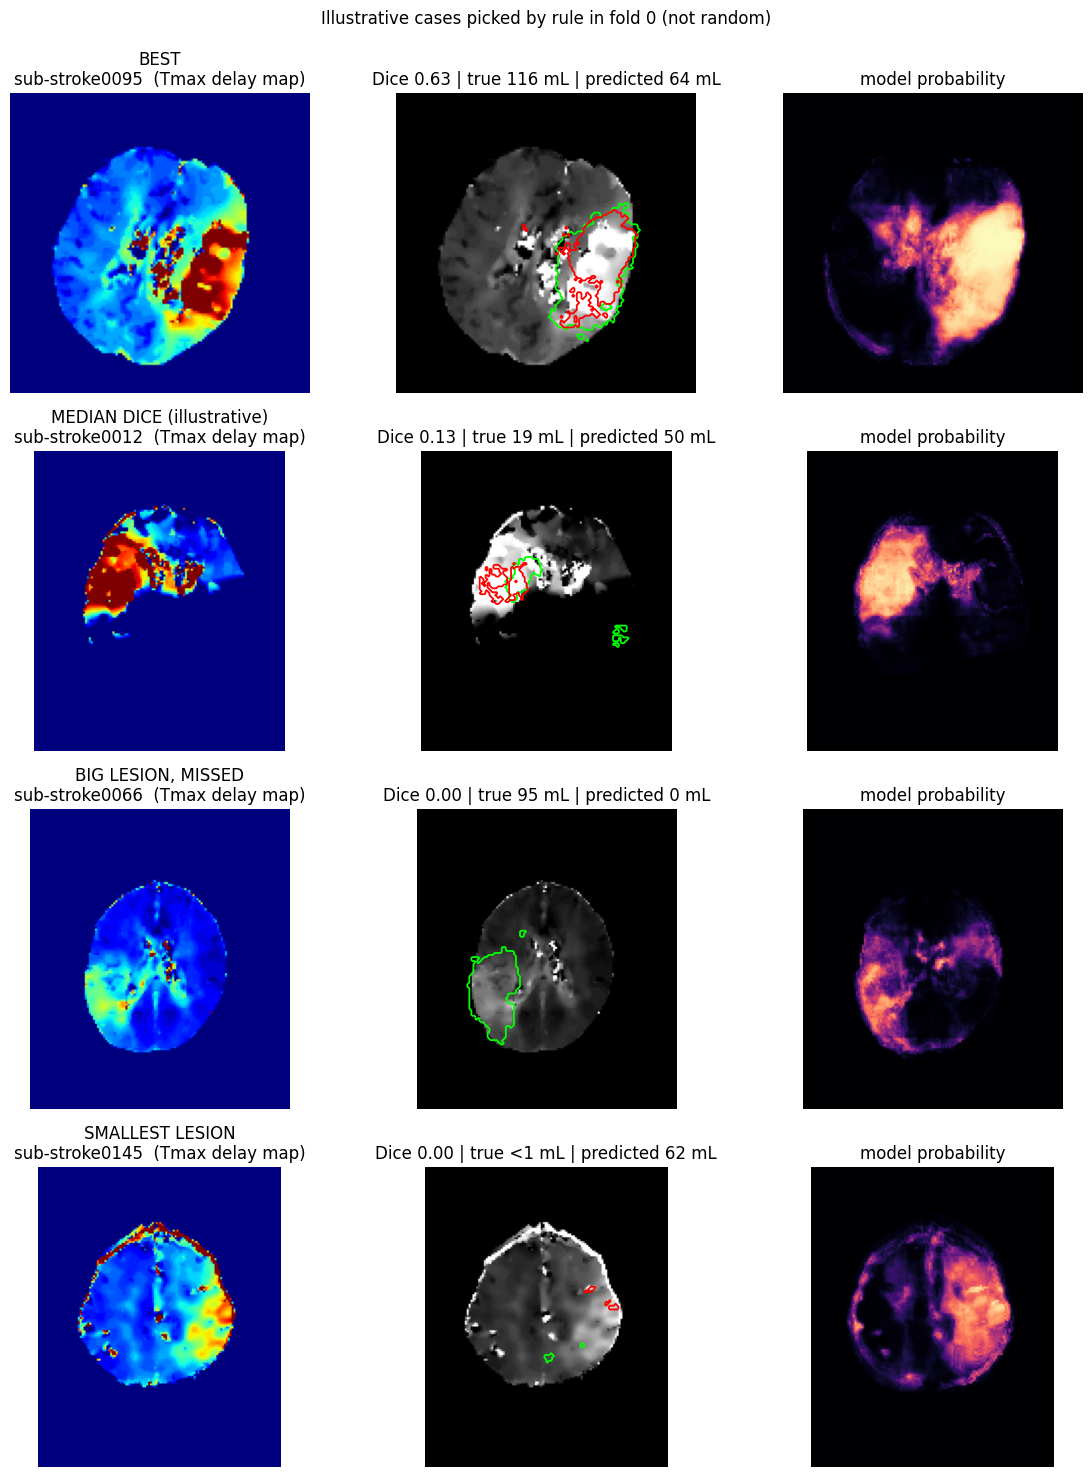

saved: /content/drive/MyDrive/isles_data/demo/failure_gallery.png


In [ ]:
R['les_ml'] = R['vol_true']
big = R[R['les_ml'] >= R['les_ml'].median()]
CASES = [('BEST', R['dice'].idxmax()), ('MEDIAN DICE (illustrative)', (R['dice'] - R['dice'].median()).abs().idxmin()),
         ('BIG LESION, MISSED', big['dice'].idxmin()), ('SMALLEST LESION', R['les_ml'].idxmin())]
def outline(ax, m, color):
    if m.any(): ax.contour(m.T.astype(float), levels=[0.5], colors=color, linewidths=1.3)
fig, axes = plt.subplots(len(CASES), 3, figsize=(12, 3.7 * len(CASES)))
for r, (label, sid) in enumerate(CASES):
    g = get(sid); tm = g['arr'][3].astype(np.float32); les = g['mask']; pv = pred_prob_volume(sid); pred = pv > M['thr']
    z = int(np.argmax(les.sum(axis=(0, 1))))
    axes[r, 0].imshow(tm[:, :, z].T, cmap='jet', origin='lower', vmin=0, vmax=12); axes[r, 0].set_title(f'{label}\n{sid}  (Tmax delay map)')
    axes[r, 1].imshow(tm[:, :, z].T, cmap='gray', origin='lower', vmin=0, vmax=12); outline(axes[r, 1], les[:, :, z], 'lime'); outline(axes[r, 1], pred[:, :, z], 'red')

    vt = R.loc[sid, "vol_true"]; vt_txt = '<1' if vt < 1 else f'{vt:.0f}'
    axes[r, 1].set_title(f'Dice {R.loc[sid, "dice"]:.2f} | true {vt_txt} mL | predicted {R.loc[sid, "vol_pred"]:.0f} mL')
    axes[r, 2].imshow(pv[:, :, z].T, cmap='magma', origin='lower', vmin=0, vmax=1); axes[r, 2].set_title('model probability');
    for a in axes[r]: a.axis('off')

fig.suptitle('Illustrative cases picked by rule in fold 0 (not random)', y=0.995)
plt.tight_layout(); os.makedirs(os.path.join(PROJECT, 'demo'), exist_ok=True)
plt.savefig(os.path.join(PROJECT, 'demo', 'failure_gallery.png'), dpi=160); plt.show()
print('saved:', os.path.join(PROJECT, 'demo', 'failure_gallery.png'))

## 3. One-patient demo (for the presentation): the maps, the prediction, the reasons, and the trust flag
Set `DEMO_ID` to a patient id from the table above, or leave `None` to use the TYPICAL patient. **Trust flag** = the finding from the study: the model should not be trusted when it predicts a small lesion; the cut-off here is the 40% smallest predicted volumes in this fold (about 60% coverage).

Setting DEMO_ID to the value 'sub-stroke0095'

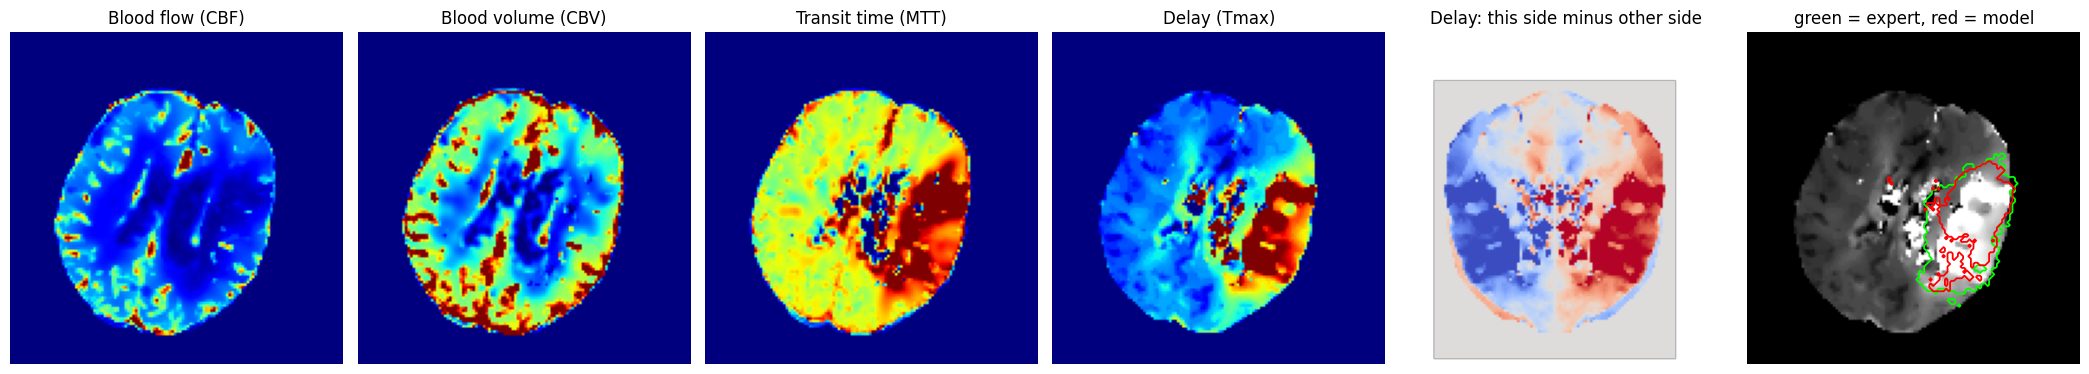

PATIENT sub-stroke0095: Dice 0.63 | expert lesion 116 mL | model predicts 64 mL

Why the model flagged the most-suspicious spot inside the lesion (push toward "damaged" = +):
   +1.79  smoothed difference from the other side in delay (Tmax)
   +0.88  smoothed transit time (MTT)
   +0.64  smoothed blood flow (CBF)
   +0.59  smoothed delay (Tmax)
   +0.55  smoothed difference from the other side in transit time (MTT)

TRUST FLAG: quiet - predicted size 64 mL is above the 24 mL cut-off.
(In this fold: mean Dice 0.195 on all patients; 0.253 on the 18 patients the flag leaves alone.)
Reminder: research demo only, not a clinical tool.


In [ ]:
import shap
DEMO_ID = 'sub-stroke0095'
demo = DEMO_ID or dict(CASES)['MEDIAN DICE (illustrative)']
PRE = {'raw': 'value of', 'rel': 'level relative to the brain average of', 'relp75': 'level relative to normal of', 'mir': 'difference from the other side in',
       'mirratio': 'ratio to the other side of', 'sm': 'smoothed', 'smmir': 'smoothed difference from the other side in', 'lstd': 'local variability of'}
MAPN = {'cbf': 'blood flow (CBF)', 'cbv': 'blood volume (CBV)', 'mtt': 'transit time (MTT)', 'tmax': 'delay (Tmax)'}
POSN = {'pos_midline_dist': 'distance from the midline', 'pos_front_back': 'front-back position', 'pos_up_down': 'up-down position'}
def plain(n):
    if n in POSN: return POSN[n]
    pre, m = n.split('_', 1); return f'{PRE[pre]} {MAPN[m]}'
g = get(demo); les = g['mask']; pv = pred_prob_volume(demo); pred = pv > M['thr']; z = int(np.argmax(les.sum(axis=(0, 1))))
fig, ax = plt.subplots(1, 6, figsize=(21, 3.9)); tm = g['arr'][3].astype(np.float32)
for i, (k, lab, vmax) in enumerate((('cbf', 'Blood flow (CBF)', 60), ('cbv', 'Blood volume (CBV)', 6), ('mtt', 'Transit time (MTT)', 20), ('tmax', 'Delay (Tmax)', 12))):
    ax[i].imshow(g['arr'][i][:, :, z].T.astype(np.float32), cmap='jet', origin='lower', vmin=0, vmax=vmax); ax[i].set_title(lab)
mv = mirror_vol(np.where(g['brain'], tm, np.nan), g['mid'])
ax[4].imshow((tm - mv)[:, :, z].T, cmap='coolwarm', origin='lower', vmin=-8, vmax=8); ax[4].set_title('Delay: this side minus other side')
ax[5].imshow(tm[:, :, z].T, cmap='gray', origin='lower', vmin=0, vmax=12); outline(ax[5], les[:, :, z], 'lime'); outline(ax[5], pred[:, :, z], 'red'); ax[5].set_title('green = expert, red = model')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(PROJECT, 'demo', 'demo_patient.png'), dpi=160); plt.show()
# why: the model's reasons at the voxel it is most sure about inside the expert lesion (or overall, if it misses the lesion entirely)
b = g['brain']; bidx = np.flatnonzero(b); inside = np.flatnonzero(les.reshape(-1)[bidx])
pick = inside[np.argmax(pv.reshape(-1)[bidx][inside])] if len(inside) else int(np.argmax(pv.reshape(-1)[bidx]))
x = FEAT[demo]['F'][pick:pick + 1].astype(np.float32); sv = shap.TreeExplainer(M['model']).shap_values(x)[0]
top = pd.Series(sv, index=FEAT_NAMES).sort_values(key=np.abs, ascending=False).head(5)
print(f'PATIENT {demo}: Dice {R.loc[demo, "dice"]:.2f} | expert lesion {R.loc[demo, "vol_true"]:.0f} mL | model predicts {R.loc[demo, "vol_pred"]:.0f} mL')
print('\nWhy the model flagged the most-suspicious spot inside the lesion (push toward "damaged" = +):')
for n, v in top.items(): print(f'   {v:+.2f}  {plain(n)}')
cut = R['vol_pred'].quantile(0.4); flagged = R.loc[demo, 'vol_pred'] < cut
print(f'\nTRUST FLAG: ' + (f'FIRES - the model predicts a small lesion ({R.loc[demo, "vol_pred"]:.0f} mL < {cut:.0f} mL): CHECK THIS ONE YOURSELF.' if flagged else f'quiet - predicted size {R.loc[demo, "vol_pred"]:.0f} mL is above the {cut:.0f} mL cut-off.'))
keep = R['vol_pred'] >= cut
print(f'(In this fold: mean Dice {R["dice"].mean():.3f} on all patients; {R.loc[keep, "dice"].mean():.3f} on the {int(keep.sum())} patients the flag leaves alone.)')
print('Reminder: research demo only, not a clinical tool.')